# 03 - Feature engineering

Shared preprocessing for the model notebooks 04–06. The result is saved to `data/processed/model_input.parquet`.
Model-specific steps (scaling, encoding, TF-IDF) are fitted on the training set only, inside each model notebook.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from experiments.data import load_data, NUMERIC, CATEGORICAL
from experiments.estimators import structured_preprocessor, native_features, text_inputs, redact_text

## Location keys

Many district and ward names exist in several places (for example "Châu Thành" or "Phường 1").
Adding the parent location to each name keeps them apart.

In [2]:
df = pd.read_parquet("../data/processed/priced_listings.parquet")

province = df["province_name"].astype("string")
df["district_name"] = province + " | " + df["district_name"].astype("string")
df["ward_name"] = df["district_name"] + " | " + df["ward_name"].astype("string")
df["street_name"] = df["district_name"] + " | " + df["street_name"].astype("string")

df[["district_name", "ward_name", "street_name"]].head()

,district_name,ward_name,street_name
0,Hà Nội | Bắc Từ Liêm,Hà Nội | Bắc Từ Liêm | Phúc Diễn,Hà Nội | Bắc Từ Liêm | Ngọa Long
1,Hồ Chí Minh | 8,Hồ Chí Minh | 8 | 5,Hồ Chí Minh | 8 | Tạ Quang Bửu
2,Vĩnh Long | Bình Minh,<NA>,<NA>
3,Hồ Chí Minh | 12,Hồ Chí Minh | 12 | Đông Hưng Thuận,Hồ Chí Minh | 12 | Nguyễn Văn Quá
4,Hồ Chí Minh | Tân Phú,Hồ Chí Minh | Tân Phú | Tân Thành,Hồ Chí Minh | Tân Phú | Nguyễn Hậu


In [3]:
df.to_parquet("../data/processed/model_input.parquet", index=False)
print(f"Saved {len(df):,} rows -> model_input.parquet")

Saved 2,397,467 rows -> model_input.parquet


## Train / validation / test split

The split follows `published_at`: the oldest 70% of listings are used for training, the next 15% for validation and the newest 15% for testing.

In [4]:
parts, manifest = load_data("data/processed/model_input.parquet")
train, val, test = parts["train"], parts["validation"], parts["test"]

for name, part in parts.items():
    print(name, len(part), part.published_at.min(), "->", part.published_at.max())

train 1678226 2025-06-01 00:01:38.762000 -> 2025-12-12 03:56:28.239000
validation 359620 2025-12-12 03:56:48.113000 -> 2026-01-28 12:53:46.509000
test 359621 2026-01-28 12:53:46.686000 -> 2026-03-30 23:59:26.036000


## Target

Prices are heavily skewed to the right, so the models are trained on `log1p(price)`.

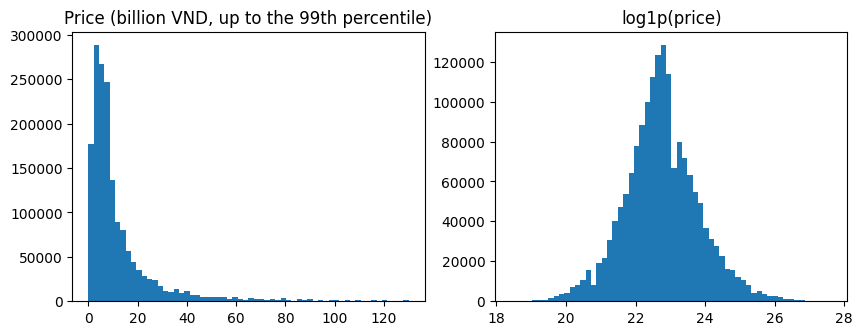

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(train.price / 1e9, bins=60, range=(0, train.price.quantile(0.99) / 1e9))
axes[0].set_title("Price (billion VND, up to the 99th percentile)")
axes[1].hist(np.log1p(train.price), bins=60)
axes[1].set_title("log1p(price)")
plt.show()

## Missing values

In [6]:
train[NUMERIC + CATEGORICAL].isna().mean().sort_values(ascending=False)

house_depth           0.966373
balcony_direction     0.837867
road_width            0.836192
floor_count           0.783596
project_name          0.719713
house_direction       0.682208
bathroom_count        0.502502
frontage_width        0.481915
bedroom_count         0.467693
street_name           0.412330
ward_name             0.170727
district_name         0.033052
area                  0.000000
property_type_name    0.000000
province_name         0.000000
dtype: float64

## One-hot encoding (Ridge, Random Forest)

Numeric columns: missing values are filled with the median, plus a column that marks them. Categorical columns: one-hot encoded; values seen fewer than 5 times are grouped together, with at most 64 columns per variable.

In [7]:
preprocessor = structured_preprocessor(scale=True).fit(train)
X_train = preprocessor.transform(train)

print("Shape:", X_train.shape)
print(preprocessor.get_feature_names_out()[:10])

Shape: (1678226, 363)
['numeric__area' 'numeric__floor_count' 'numeric__frontage_width'
 'numeric__house_depth' 'numeric__road_width' 'numeric__bedroom_count'
 'numeric__bathroom_count' 'numeric__missingindicator_floor_count'
 'numeric__missingindicator_frontage_width'
 'numeric__missingindicator_house_depth']


## Native categories (LightGBM, CatBoost)

The categorical columns are used directly, without one-hot encoding. For LightGBM, a value that never appears in the training set becomes NaN.
The table counts these unseen values in the test set.

In [8]:
X_train_lgb, levels = native_features(train)
X_test_lgb, _ = native_features(test, levels)

X_test_lgb[CATEGORICAL].isna().sum().to_frame("unseen in train")

,unseen in train
property_type_name,0
province_name,0
district_name,27
ward_name,194
street_name,1374
project_name,2101
house_direction,24
balcony_direction,1


## Text (TF-IDF)

Sentences that mention a price and words with digits are removed, so the model cannot read the price straight from the text.

In [9]:
example = "Bán nhà mặt tiền Quận 1, giá 12,5 tỷ, sổ hồng chính chủ."
print(example)
print(redact_text(example))

text_inputs(train.head()).to_frame("text")

Bán nhà mặt tiền Quận 1, giá 12,5 tỷ, sổ hồng chính chủ.
ban nha mat tien quan so hong chinh chu


,text
0,ban nhanh nha tang thang may ngoa long cau die...
1,ban gap nha mat tien tang khu phan lo ta quang...
2,ban biet thu gan san bong binh minh duong rong...
3,can ban can ho cc thai an nguyen van qua chung...
4,mtkd p tan thanh tan phu mtkd p tan thanh tan ...
